In [ ]:
!unrar x -inul imagenes_quirpinchaca.rar

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


ruta_carpeta = "imagenes_quirpinchaca"
LADO = 64

lista_recortes_img = []
lista_recortes_planos = []

for archivo in os.listdir(ruta_carpeta):
    if archivo.lower().endswith((".jpg", ".jpeg", ".png")):
        ruta_completa = os.path.join(ruta_carpeta, archivo)
        try:
            with Image.open(ruta_completa) as img:
                img = img.convert("RGB")
                ancho, alto = img.size


                if min(ancho, alto) > 600:
                    escala = 512 / min(ancho, alto)
                    img = img.resize((int(ancho * escala), int(alto * escala)), Image.Resampling.LANCZOS)
                    ancho, alto = img.size


                for y in range(0, alto - LADO + 1, LADO):
                    for x in range(0, ancho - LADO + 1, LADO):
                        recorte = img.crop((x, y, x + LADO, y + LADO))
                        arreglo = np.asarray(recorte, dtype=np.float32) / 255.0

                        lista_recortes_img.append(arreglo)
                        lista_recortes_planos.append(arreglo.flatten())
        except Exception as e:
            print(f"Error con {archivo}: {e}")

X = np.array(lista_recortes_planos)
X_img = np.array(lista_recortes_img)

print(f"Total de recortes (m): {X.shape[0]}")
print(f"Características por recorte (n): {X.shape[1]}")

Total de recortes (m): 2790
Características por recorte (n): 12288


Recortes para entrenar: 2232
Recortes reservados para validar (Test): 558

Calculando métricas de clustering (tardará unos 15-20 segundos)...


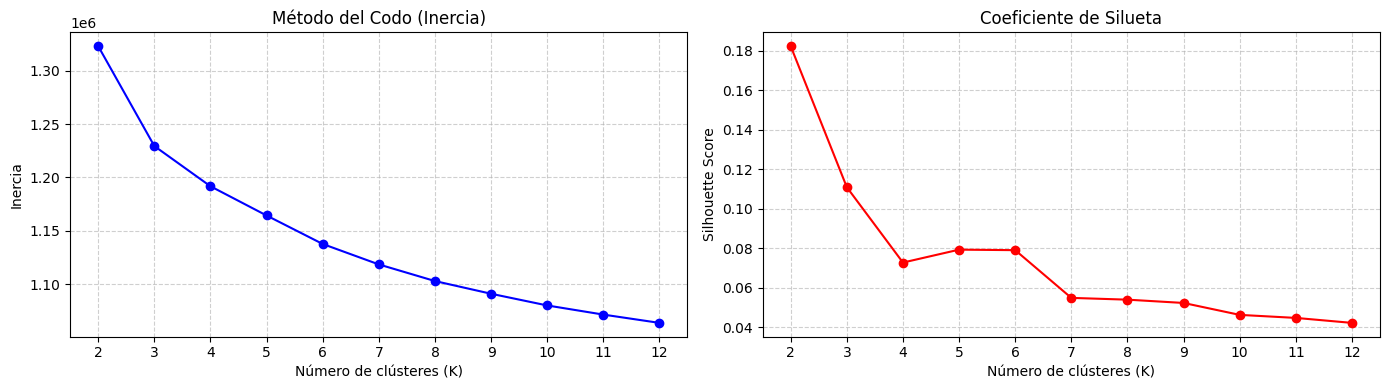

In [ ]:

X_train, X_test, img_train, img_test = train_test_split(
    X, X_img, test_size=0.20, random_state=42
)
print(f"Recortes para entrenar: {X_train.shape[0]}")
print(f"Recortes reservados para validar (Test): {X_test.shape[0]}")


inercia = []
siluetas = []
rango_k = range(2, 13)

print("\nCalculando métricas de clustering (tardará unos 15-20 segundos)...")
for k in rango_k:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    etiquetas = km.fit_predict(X_train)
    inercia.append(km.inertia_)
    siluetas.append(silhouette_score(X_train, etiquetas))


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.plot(list(rango_k), inercia, 'bo-')
ax1.set_xticks(list(rango_k))
ax1.set_xlabel("Número de clústeres (K)")
ax1.set_ylabel("Inercia")
ax1.set_title("Método del Codo (Inercia)")
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(list(rango_k), siluetas, 'ro-')
ax2.set_xticks(list(rango_k))
ax2.set_xlabel("Número de clústeres (K)")
ax2.set_ylabel("Silhouette Score")
ax2.set_title("Coeficiente de Silueta")
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

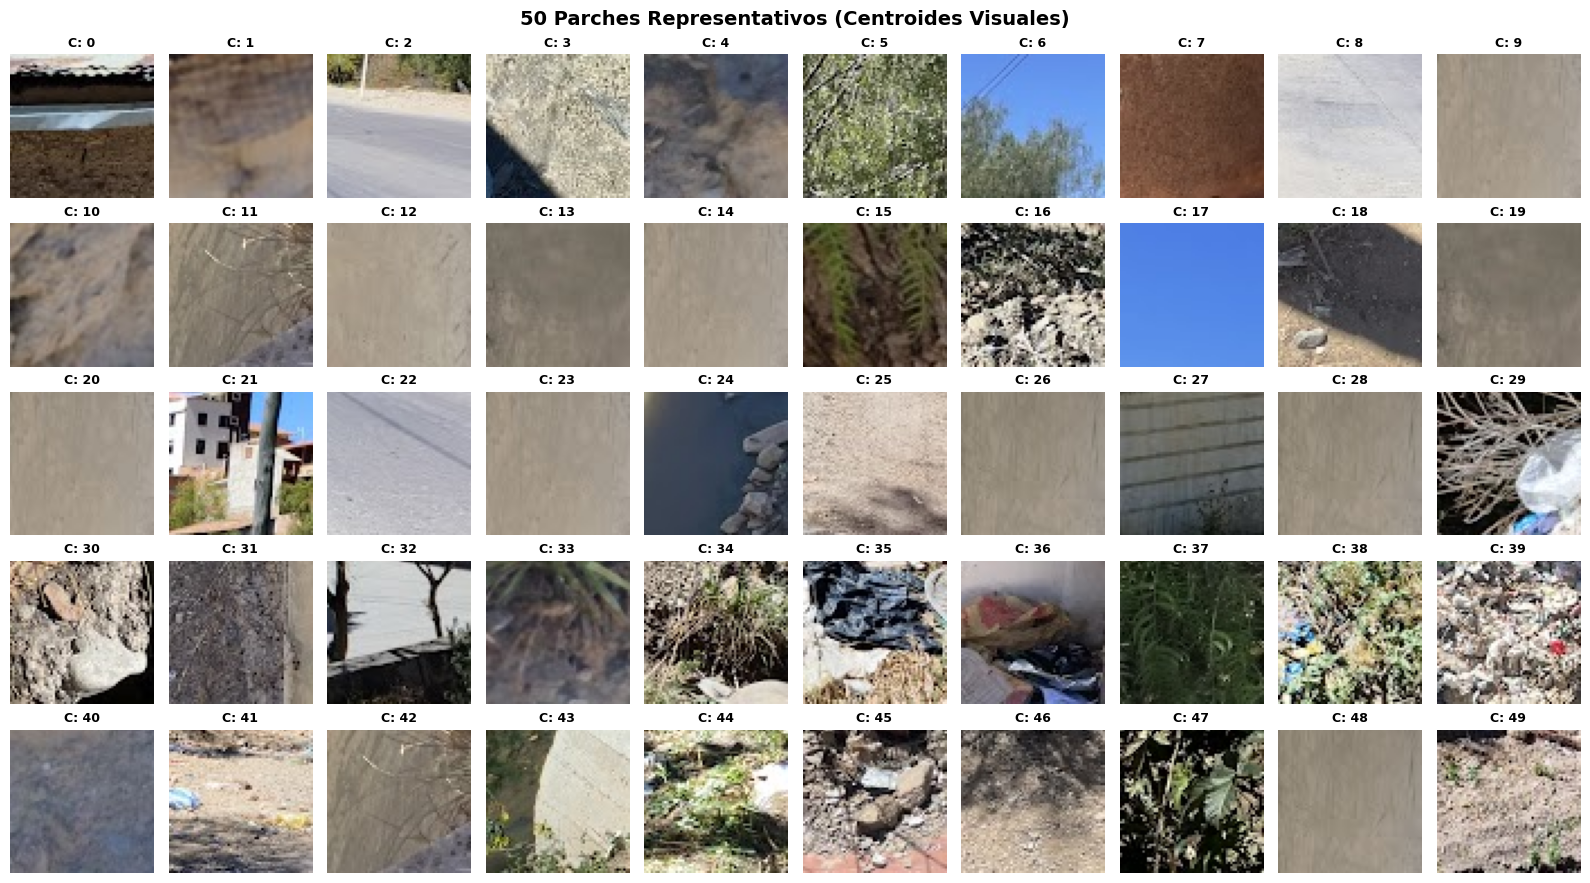

In [ ]:

k_semi = 50
kmeans_semi = KMeans(n_clusters=k_semi, init="k-means++", n_init=10, random_state=42)
clusters_train = kmeans_semi.fit_predict(X_train)


distancias_train = kmeans_semi.transform(X_train)


indices_rep = np.argmin(distancias_train, axis=0)


fig, axes = plt.subplots(5, 10, figsize=(16, 9))
for i, ax in enumerate(axes.flat):
    idx = indices_rep[i]
    ax.imshow(img_train[idx])
    ax.set_title(f"C: {i}", fontsize=9, fontweight="bold")
    ax.axis("off")

plt.suptitle("50 Parches Representativos (Centroides Visuales)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay

nombres_clases = ["Cielo", "Vegetacion", "Suelo/Rocas/Construccion"]


mapa_clusters = {
    0: 2,  1: 2,  2: 2,  3: 2,  4: 2,  5: 1,  6: 0,  7: 2,  8: 2,  9: 2,
    10: 2, 11: 2, 12: 2, 13: 2, 14: 2, 15: 1, 16: 2, 17: 0, 18: 2, 19: 2,
    20: 2, 21: 2, 22: 2, 23: 2, 24: 2, 25: 2, 26: 2, 27: 2, 28: 2, 29: 2,
    30: 2, 31: 2, 32: 2, 33: 1, 34: 1, 35: 2, 36: 2, 37: 1, 38: 1, 39: 2,
    40: 2, 41: 2, 42: 2, 43: 2, 44: 1, 45: 2, 46: 2, 47: 1, 48: 2, 49: 2
}


y_train_propagado = np.array([mapa_clusters[c] for c in clusters_train])


dist_al_centroide = distancias_train[np.arange(len(X_train)), clusters_train]
mascara_confianza = np.zeros(len(X_train), dtype=bool)

for c in range(k_semi):
    indices_c = np.where(clusters_train == c)[0]
    if len(indices_c) > 0:
        umbral = np.percentile(dist_al_centroide[indices_c], 60)
        mascara_confianza[indices_c] = dist_al_centroide[indices_c] <= umbral

X_train_final = X_train[mascara_confianza]
y_train_final = y_train_propagado[mascara_confianza]

print(f"Parches etiquetados semi-supervisadamente: {len(X_train_final)}")
for id_clase, nombre in enumerate(nombres_clases):
    print(f"  - {nombre}: {np.sum(y_train_final == id_clase)} parches")


modelo_clasificador = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
modelo_clasificador.fit(X_train_final, y_train_final)
print("\n¡Modelo supervisado entrenado con éxito!")

Parches etiquetados semi-supervisadamente: 1345
  - Cielo: 30 parches
  - Vegetacion: 80 parches
  - Suelo/Rocas/Construccion: 1235 parches

¡Modelo supervisado entrenado con éxito!


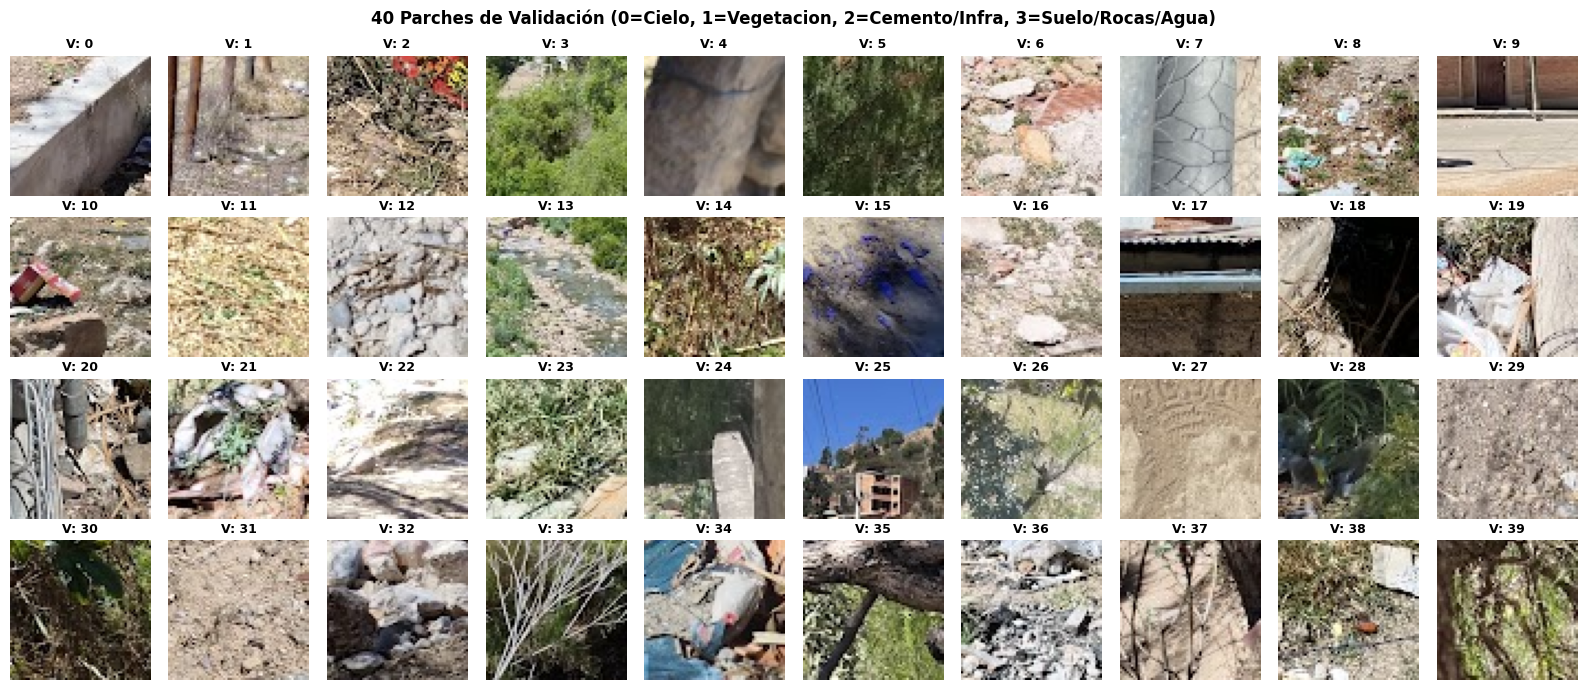

In [ ]:

np.random.seed(42)
indices_val = np.random.choice(len(X_test), size=40, replace=False)
X_val = X_test[indices_val]
img_val = img_test[indices_val]

fig, axes = plt.subplots(4, 10, figsize=(16, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(img_val[i])
    ax.set_title(f"V: {i}", fontsize=9, fontweight="bold")
    ax.axis("off")

plt.suptitle("40 Parches de Validación (0=Cielo, 1=Vegetacion, 2=Cemento/Infra, 3=Suelo/Rocas/Agua)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

=== MÉTRICAS DE VALIDACIÓN DEL MODELO ===
Exactitud General (Accuracy): 85.00%

Reporte de Clasificación:
                          precision    recall  f1-score   support

                   Cielo       1.00      1.00      1.00         1
              Vegetacion       1.00      0.33      0.50         9
Suelo/Rocas/Construccion       0.83      1.00      0.91        30

                accuracy                           0.85        40
               macro avg       0.94      0.78      0.80        40
            weighted avg       0.88      0.85      0.82        40



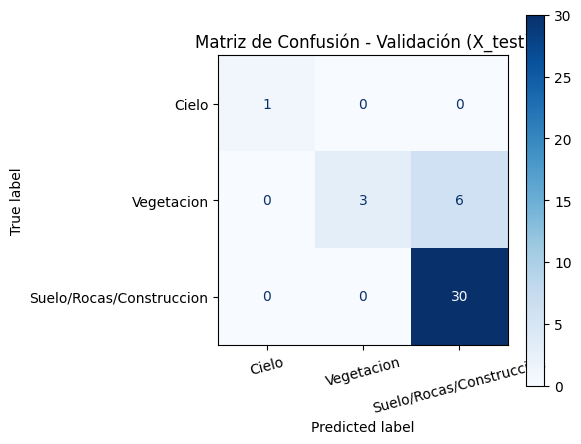

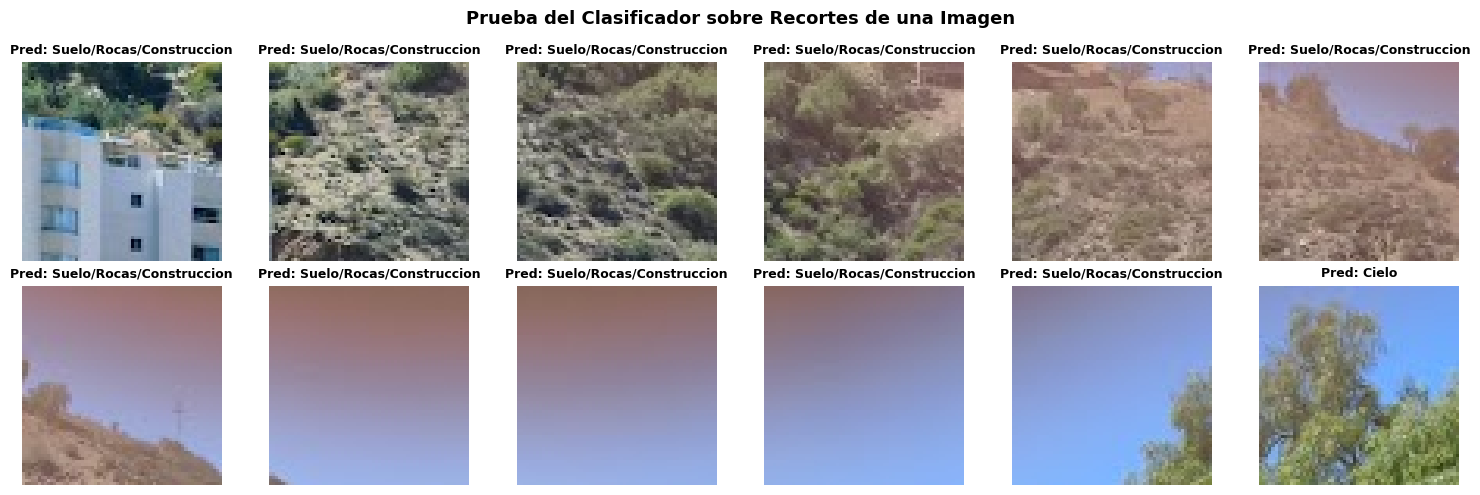

In [ ]:

y_val_real = np.array([
    2, 2, 2, 1, 2, 1, 2, 2, 2, 2,  # V: 0 al 9
    2, 2, 2, 2, 2, 2, 2, 2, 2, 2,  # V: 10 al 19
    2, 2, 2, 1, 2, 0, 1, 2, 1, 2,  # V: 20 al 29
    1, 2, 2, 1, 2, 1, 2, 2, 2, 1   # V: 30 al 39
])

y_val_pred = modelo_clasificador.predict(X_val)

exactitud = accuracy_score(y_val_real, y_val_pred)
print(f"=== MÉTRICAS DE VALIDACIÓN DEL MODELO ===")
print(f"Exactitud General (Accuracy): {exactitud * 100:.2f}%\n")
print("Reporte de Clasificación:")
print(classification_report(
    y_val_real,
    y_val_pred,
    target_names=nombres_clases,
    zero_division=0
))


fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_val_real, y_val_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nombres_clases)
disp.plot(cmap="Blues", ax=ax, values_format="d")
plt.title("Matriz de Confusión - Validación (X_test)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
pred_demo = modelo_clasificador.predict(X_demo)

fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(parches_demo[i])
    ax.set_title(f"Pred: {nombres_clases[pred_demo[i]]}", fontsize=9, fontweight="bold")
    ax.axis("off")
plt.suptitle("Prueba del Clasificador sobre Recortes de una Imagen", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()